# seq2PRINT: footprints from sequence, per tissue domain

[PRINT](t_print_footprint.ipynb) reads footprints off measured Tn5 cuts.
**seq2PRINT** (from [scPrinter](https://github.com/buenrostrolab/scPrinter))
learns to predict them from DNA: a dilated CNN reads 1,840 bp and outputs
PRINT's footprint z-score at 99 sizes (radius 2-100 bp) across the central
800 bp, plus the window's log coverage. LoRA then adapts one trained model
to each cell state.

This tutorial trains the model on a spatial ATAC section of mouse brain,
splits the section into chromatin domains, fine-tunes one LoRA state per
domain, and asks two questions:

1. **Does the domain model predict how domains differ?** A single bulk model
   gives every domain the same prediction, so between-domain differences are
   the test that only state-specific models can pass. Scoring each domain with
   every other domain's state checks that domain identity, not extra training,
   explains any gain.
2. **What does each motif do to the footprint?** Planting a motif into
   background sequences and measuring the change in predicted footprints at
   every size (scPrinter's *delta effects*) separates TF-sized footprints from
   nucleosome-scale changes.

```python
model = epi.models.seq2print.build_seq2print()                       # scPrinter's architecture
data  = epi.models.seq2print.Seq2PRINTDataset(peaks, fasta=..., reader=..., bias=..., groups=...)
res   = epi.models.seq2print.fit(model, data.split(train), data.split(valid))
model.add_lora(domain_embeddings, coverages=...)                      # one state per domain
foot, cov = epi.models.seq2print.delta_effects(model, motifs, backgrounds, state=0)
```

The network blocks and training targets are scPrinter's, vendored verbatim:
the same weights give bit-identical predictions and checkpoints load either
way (last section). The training path is Epione's: windows are read from the
fragments file with an on-demand Tn5 bias, and training is one function
call instead of scPrinter's JSON config, CLI and per-group bigWig export.

Base-resolution attributions (DeepSHAP, ISM) work the same way for every
sequence model in Epione and are not repeated here; see the gReLU bridge
(`epi.models.grelu.attributions`), which accepts seq2PRINT models and LoRA
states.

**Data.** GSE308623 `P2S1`: mouse brain at postnatal day 2, spatial ATAC,
7,131 spots, 106 M fragments (the same sample as the
[scooby](t_scooby_bridge.ipynb) and [PRINT](t_print_footprint.ipynb)
tutorials).

## Part 1 · Setup

In [1]:
%matplotlib inline
import os, sys, pathlib, re, copy, warnings
warnings.filterwarnings('ignore', module='tqdm')
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import pysam
import scanpy as sc
import torch


def _find_repo(start):
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import epione as epi
from epione._insertions import InsertionReader
s2p = epi.models.seq2print

DATA  = pathlib.Path(os.environ.get('SCOOBY_TUTORIAL_DATA', (CODE or pathlib.Path.cwd()).parent))
FRAG  = DATA / 'scooby_bench' / 'P2S1.fragments.tsv.gz'
POS   = DATA / 'scooby_bench' / 'P2S1.positions.csv'
FASTA = DATA / 'genome' / 'mm10' / 'mm10.fa'          # whole genome: folds are by chromosome
WORK  = DATA / 'seq2print_tutorial'; WORK.mkdir(exist_ok=True)
for p in (FRAG, POS, FASTA):
    if not p.exists():
        raise FileNotFoundError(f'{p}: see "Getting the inputs" in t_scooby_bridge; '
                                'mm10.fa is hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.fa.gz')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

epi.pl.plot_set()
C = sc.pl.palettes.default_20                      # scanpy's categorical colours, in order

device: cuda NVIDIA H100 80GB HBM3


└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Part 2 · Chromatin domains of the section

The scATAC recipe applies to spots unchanged (as in the
[spatial ATAC tutorial](t_spatial_atac.ipynb)): a 500 bp tile matrix, the
50,000 most accessible tiles, the BiRMT-2 embedding. A spot here holds about
15,000 fragments, so the embedding is smoothed over each spot's four grid
neighbours before k-means splits it into six domains.

In [2]:
%%time
pos = (pd.read_csv(POS, header=None, names=['bc', 'in_tissue', 'row', 'col', 'pr', 'pc'])
         .query('in_tissue == 1').reset_index(drop=True))
barcodes = (pos['bc'] + '-1').tolist()
fa = pysam.FastaFile(str(FASTA))
CHROMS = [f'chr{i}' for i in range(1, 20)] + ['chrX']
sizes = {c: fa.get_reference_length(c) for c in CHROMS}

atac = epi.pp.import_fragments(str(FRAG), sizes, whitelist=barcodes, min_num_fragments=0)
atac = atac[barcodes].copy()                                 # spot order = positions table
atac.obs['array_row'], atac.obs['array_col'] = pos['row'].to_numpy(), pos['col'].to_numpy()
atac.obsm['spatial'] = np.c_[pos['col'], -pos['row']].astype(float)
epi.pp.add_tile_matrix(atac, bin_size=500)
epi.pp.select_features(atac, n_features=50000)
tiles = atac[:, atac.var['selected'].to_numpy(bool)].copy()
epi.tl.birmt(tiles)
# Richer embedding, used for the LoRA states. At ~15,000 fragments per spot its
# inner Leiden step finds one cluster, so it keeps the most accessible tiles
# (a plain LSI); the warnings that case raises are silenced here.
sc.settings.verbosity = 0
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    epi.tl.iterative_lsi(tiles, n_components=30, verbose=False)
sc.settings.verbosity = 3
epi.tl.spatial_neighbors(tiles, coord_type='grid', n_neighs=4)
epi.tl.spatial_smooth(tiles, use_rep='X_birmt', lam=0.5)
epi.tl.spatial_domains(tiles, 6, use_rep='X_birmt_smooth', method='kmeans', use_pca=False,
                       key_added='domain')
tiles.obs['domain'] = ('D' + tiles.obs['domain'].astype(str)).astype('category')
DOMAINS = sorted(tiles.obs['domain'].cat.categories, key=lambda d: int(d[1:]))
DCOL = dict(zip(DOMAINS, C))
tiles.obs.groupby('domain', observed=True)['n_fragment'].agg(spots='size', fragments='sum')

└─ scanning $SCOOBY_TUTORIAL_DATA/scooby_bench/P2S1.fragments.tsv.gz


  └─ imported 7,131 cells  (106,281,702 unique fragments)


└─ building tile matrix: 7,131 cells × 5,267,565 tiles (500 bp bins, strategy=paired-insertion)


  └─ tile matrix nnz=158,516,286


└─ Selected 50,000 features.


  └─ [birmt2] 7,131 cells x 50,000 peaks (min_cells=18); shrinkage=score tiles=[] seq_lambda=0.0


  └─ [birmt2] level-0 timings (s) transpose/sinkhorn/subsample/gram/eig/-/krylov: 0.0 0.0 0.0 0.0 0.7 0.0 0.1
  └─ [birmt2] level peaks: rank=3 alpha=0.9816 beta=0 ks=0.01282 n_features=50000 (1.0s)


CPU times: user 1min 55s, sys: 8.07 s, total: 2min 3s
Wall time: 41.7 s


,spots,fragments
domain,,
D1,2270,37817697
D2,1112,17069146
D3,1016,13906402
D4,337,4714272
D5,1168,18034057
D6,1228,14740128


Promoter accessibility of marker genes names most domains. Each value is the
domain's share of cuts within 2.5 kb of the gene's TSS, z-scored across
domains (GENCODE vM25 genes, downloaded once).

  └─ Reading GTF file from $SCOOBY_TUTORIAL_DATA/seq2print_tutorial/gencode.vM25.basic.annotation.gtf.gz...


  └─ GTF file read successfully


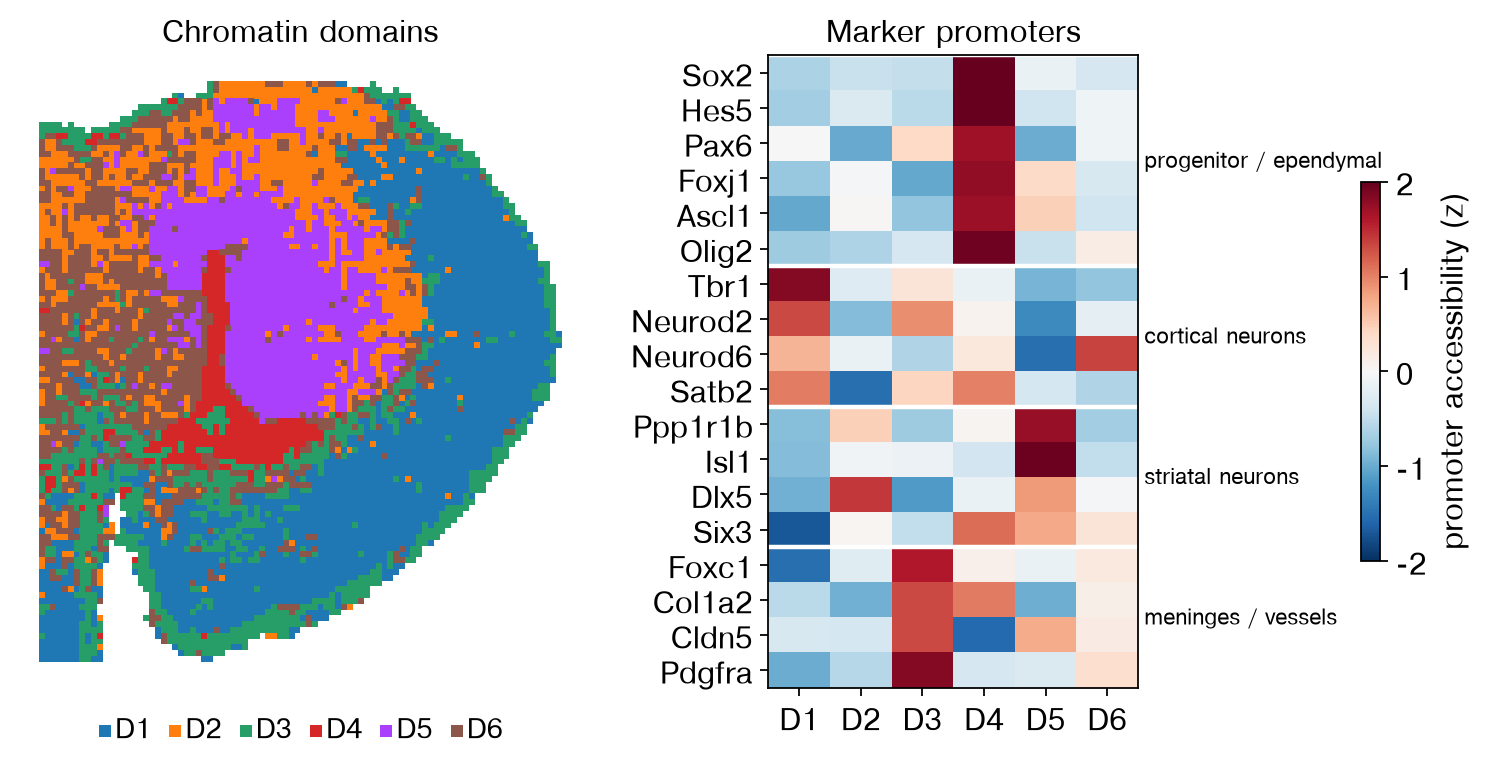

CPU times: user 28.9 s, sys: 1.44 s, total: 30.3 s
Wall time: 30.3 s


In [3]:
%%time
GTF = WORK / 'gencode.vM25.basic.annotation.gtf.gz'
if not GTF.exists():
    import urllib.request
    urllib.request.urlretrieve('https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_mouse/release_M25/'
                               'gencode.vM25.basic.annotation.gtf.gz', GTF)
genes = epi.io.read_gtf(str(GTF), feature_whitelist=['gene'], keep_attribute=False)
genes = genes.drop_duplicates('gene_name').set_index('gene_name')
tss = np.where(genes['strand'] == '+', genes['start'], genes['end'])
genes['tss'] = tss

# pseudobulk tile counts per domain: [domains x tiles]
spot_domain = tiles.obs['domain'].to_numpy()
G = sp.csr_matrix((np.ones(len(spot_domain)), ([DOMAINS.index(d) for d in spot_domain], np.arange(len(spot_domain)))),
                  shape=(len(DOMAINS), len(spot_domain)))
P = np.asarray((G @ sp.csr_matrix(atac.X)).todense(), dtype=np.float64)
tile_chrom = atac.var_names.str.split(':').str[0].to_numpy()
tile_start = atac.var_names.str.split(':').str[1].str.split('-').str[0].astype(int).to_numpy()
tile_index = {(c, s // 500): i for i, (c, s) in enumerate(zip(tile_chrom, tile_start))}
cpm = P / P.sum(1, keepdims=True) * 1e6

MARKERS = {'progenitor / ependymal': ['Sox2', 'Hes5', 'Pax6', 'Foxj1', 'Ascl1', 'Olig2'],
           'cortical neurons': ['Tbr1', 'Neurod2', 'Neurod6', 'Satb2'],
           'striatal neurons': ['Ppp1r1b', 'Isl1', 'Dlx5', 'Six3'],
           'meninges / vessels': ['Foxc1', 'Col1a2', 'Cldn5', 'Pdgfra']}
rows = {}
for group, gs in MARKERS.items():
    for g in gs:
        c, t = genes.loc[g, 'seqname'], int(genes.loc[g, 'tss'])
        ii = [tile_index[(c, b)] for b in range(t // 500 - 5, t // 500 + 6) if (c, b) in tile_index]
        rows[(group, g)] = cpm[:, ii].sum(1)
marker = pd.DataFrame(rows, index=DOMAINS).T
marker_z = marker.sub(marker.mean(1), axis=0).div(marker.std(1), axis=0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={'width_ratios': [1, 1.05]})
xy = tiles.obsm['spatial']
for d in DOMAINS:
    m = spot_domain == d
    a1.scatter(xy[m, 0], xy[m, 1], s=7, marker='s', lw=0, color=DCOL[d], label=d)
a1.set_aspect('equal'); a1.axis('off'); a1.set_title('Chromatin domains')
a1.legend(loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=6, frameon=False, markerscale=2,
          handletextpad=0.1, columnspacing=0.6)
im = a2.imshow(marker_z.to_numpy(), cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
a2.set_xticks(range(len(DOMAINS)), DOMAINS)
a2.set_yticks(range(len(marker_z)), [g for _, g in marker_z.index])
y0 = 0
for group, gs in MARKERS.items():
    a2.axhline(y0 - 0.5, color='w', lw=2)
    a2.text(len(DOMAINS) - 0.4, y0 + (len(gs) - 1) / 2, group, va='center', ha='left', fontsize=10)
    y0 += len(gs)
fig.colorbar(im, ax=a2, shrink=0.6, pad=0.32, label='promoter accessibility (z)')
a2.set_title('Marker promoters')
plt.show()

D4 lines the lateral ventricle and has the progenitor and ependymal promoters
open (Sox2, Hes5, Pax6, Foxj1, Olig2); D1 is the cortex (Tbr1, Neurod2); D5
the striatum (Ppp1r1b, Isl1); D3 the outer rim, with meningeal and vascular
promoters (Foxc1, Pdgfra, Col1a2). D2 and D6 are intermixed regions without a
clear marker profile. The domains are 0.3 to 2.3 thousand spots and 5 to 38
million fragments each.

## Part 3 · Peaks and folds

Two peak sets, both as 500 bp windows centred on a tile:

* **bulk peaks** — the 10,000 tiles with the most cuts genome-wide (mostly
  promoters and other constitutive sites); the bulk model is trained on these;
* **domain peaks** — for each domain, the 600 tiles (of those with at least 150
  cuts) most enriched in that domain relative to the rest of the section.
  These are where a domain model has something to predict.

The split is **scPrinter's fold 0 for mm10**: whole chromosomes for train,
validation and test, so no held-out window shares sequence with training.

In [4]:
%%time
peak_file = WORK / 'peaks_top10000.tsv'
if peak_file.exists():
    bulk_peaks = pd.read_csv(peak_file, sep='\t')
else:                                   # densest 500 bp bins by insertion count
    keep, cnt = set(barcodes), {}
    tbx = pysam.TabixFile(str(FRAG))
    for c in CHROMS:
        for line in tbx.fetch(c):
            f = line.split('\t', 4)
            if f[3] in keep:
                for p in (int(f[1]), int(f[2])):
                    cnt[(c, p // 500)] = cnt.get((c, p // 500), 0) + 1
    top = sorted(cnt.items(), key=lambda kv: -kv[1])[:10_000]
    bulk_peaks = pd.DataFrame({'chrom': [k[0] for k, _ in top],
                               'summit': [k[1] * 500 + 250 for k, _ in top],
                               'cuts': [n for _, n in top]})
    bulk_peaks.to_csv(peak_file, sep='\t', index=False)

ok = P.sum(0) >= 150
rest = P.sum(0, keepdims=True) - P
lfc = np.log2((cpm + 2) / (rest / rest.sum(1, keepdims=True) * 1e6 + 2))
dom_peaks = []
for k, d in enumerate(DOMAINS):
    top = np.argsort(-np.where(ok, lfc[k], -np.inf))[:600]
    dom_peaks.append(pd.DataFrame({'chrom': tile_chrom[top], 'summit': tile_start[top] + 250,
                                   'domain': d, 'log2_enrichment': lfc[k, top]}))
dom_peaks = pd.concat(dom_peaks)
print(dom_peaks.groupby('domain')['log2_enrichment'].median().round(2).to_dict())

peaks = (pd.concat([bulk_peaks[['chrom', 'summit']].assign(kind='bulk'),
                    dom_peaks[['chrom', 'summit', 'domain']].assign(kind='domain')])
           .drop_duplicates(['chrom', 'summit']).reset_index(drop=True))
folds = s2p.chromosome_folds('mm10', 0)
peaks['split'] = np.select([peaks.chrom.isin(folds[s]) for s in ('train', 'valid', 'test')],
                           ['train', 'valid', 'test'], 'unused')
pd.crosstab(peaks['kind'], peaks['split'])

{'D1': 0.33, 'D2': 0.39, 'D3': 0.43, 'D4': 1.05, 'D5': 0.67, 'D6': 0.42}
CPU times: user 459 ms, sys: 221 ms, total: 680 ms
Wall time: 682 ms


split,test,train,valid
kind,,,
bulk,2172,5654,2174
domain,541,1559,626


## Part 4 · The bulk model

`Seq2PRINTDataset` reads each window once from the fragments: 1,840 bp of
sequence and a 1 kb track of insertions and Tn5 bias around the summit. The
footprint target is computed from those two tracks on the fly at every
training step (scPrinter's augmentation: shared jitter up to ±128 bp,
reverse complement, 30 random scales). The bias is PRINT's CNN, run on the
GPU in one pass per window (`exact=False`, equal to scPrinter's genome-wide
bias up to float32 rounding).

Training follows scPrinter's recipe (AdamW, bf16, an exponential moving
average of the weights, early stopping) and takes about 10 minutes on an
H100, so by default the trained model is **downloaded from Hugging Face**
([`starlitnightly/epione-seq2print`](https://huggingface.co/starlitnightly/epione-seq2print),
~47 MB, pinned and md5-checked; its manifest carries the training history).
Set `TRAIN = True` to retrain.

In [5]:
%%time
bias = epi.tl.tn5_bias(FASTA, device=DEVICE, exact=False)
dispersion = epi.tl.DispersionModel.load()
target_model = s2p.footprint_target_model(dispersion)
model = s2p.build_seq2print()


def windows(table, groups=None):
    reader = InsertionReader(FRAG, barcodes, shift=bias.shift)
    return s2p.Seq2PRINTDataset(table, fasta=FASTA, reader=reader, bias=bias,
                                groups=groups, dna_len=model.dna_len)


bulk = windows(bulk_peaks)
train, valid, test = (bulk.split(folds[s]) for s in ('train', 'valid', 'test'))
print({'train': len(train), 'valid': len(valid), 'test': len(test)})

TRAIN = False                                     # True: train instead of downloading
ckpt, hist_file = WORK / 'bulk_fold0.pt', WORK / 'bulk_fold0_history.tsv'
if not TRAIN and 'p2s1_fold0_bulk' in s2p.PRETRAINED:
    model, manifest = s2p.load_pretrained('p2s1_fold0_bulk', return_manifest=True)
    hist = pd.DataFrame(manifest['history'])
elif ckpt.exists() and hist_file.exists():
    model.load_state_dict(torch.load(ckpt, map_location='cpu'))
    hist = pd.read_csv(hist_file, sep='\t')
else:
    res = s2p.fit(model, train, valid, epochs=60, patience=5, num_workers=6,
                  device=DEVICE, target_model=target_model)
    model, hist = res.model, res.to_frame()
    torch.save(model.state_dict(), ckpt)
    hist.to_csv(hist_file, sep='\t', index=False)
model = model.to(DEVICE).eval()
best_epoch = int(hist.valid_loss.idxmin())
metrics_bulk = s2p.evaluate(model, test, target_model=target_model, device=DEVICE)
print(f'best epoch {best_epoch} of {len(hist)}; test chromosomes:',
      {k: round(v, 3) for k, v in metrics_bulk.items()})

└─ Seq2PRINTDataset: 9,998 peaks x 1 group(s) (0 at contig edges, 2 outside coverage bounds dropped)
{'train': 5653, 'valid': 2174, 'test': 2171}


best epoch 28 of 34; test chromosomes: {'loss': 0.964, 'profile_pearson': 0.53, 'footprint_pearson': 0.534, 'coverage_pearson': 0.149}
CPU times: user 26.5 s, sys: 2.48 s, total: 29 s
Wall time: 28 s


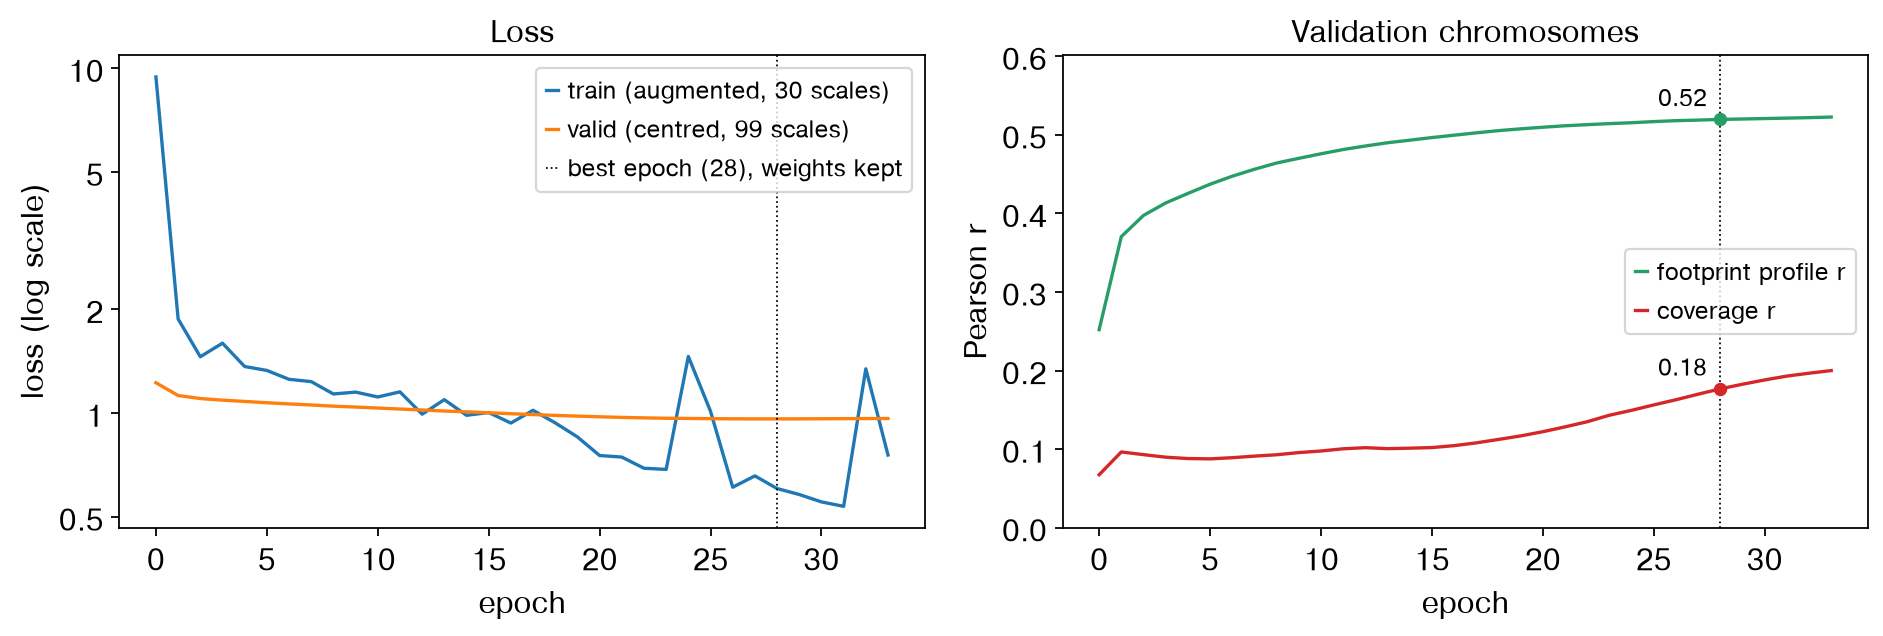

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.plot(hist.epoch, hist.train_loss, color=C[0], label='train (augmented, 30 scales)')
a1.plot(hist.epoch, hist.valid_loss, color=C[1], label='valid (centred, 99 scales)')
a1.set_yscale('log')                              # epoch 0's train loss would flatten the rest
a1.set_yticks([0.5, 1, 2, 5, 10], ['0.5', '1', '2', '5', '10']); a1.minorticks_off()
a1.axvline(best_epoch, color='k', lw=0.8, ls=':', label=f'best epoch ({best_epoch}), weights kept')
a1.set_xlabel('epoch'); a1.set_ylabel('loss (log scale)'); a1.legend(loc='upper right', fontsize=11)
a1.set_title('Loss')
for col, c, lab in (('valid_profile_pearson', C[2], 'footprint profile r'),
                    ('valid_coverage_pearson', C[3], 'coverage r')):
    v = hist[col].iloc[best_epoch]
    a2.plot(hist.epoch, hist[col], color=c, label=lab)
    a2.plot(best_epoch, v, 'o', ms=5, color=c, zorder=3)
    a2.annotate(f'{v:.2f}', xy=(best_epoch, v), xytext=(-6, 6), textcoords='offset points',
                ha='right', fontsize=11)
a2.axvline(best_epoch, color='k', lw=0.8, ls=':')
a2.set_xlabel('epoch'); a2.set_ylabel('Pearson r')
a2.set_ylim(0, 1.15 * hist.valid_profile_pearson.max())
a2.legend(loc='center right', fontsize=11); a2.set_title('Validation chromosomes')
plt.tight_layout(); plt.show()

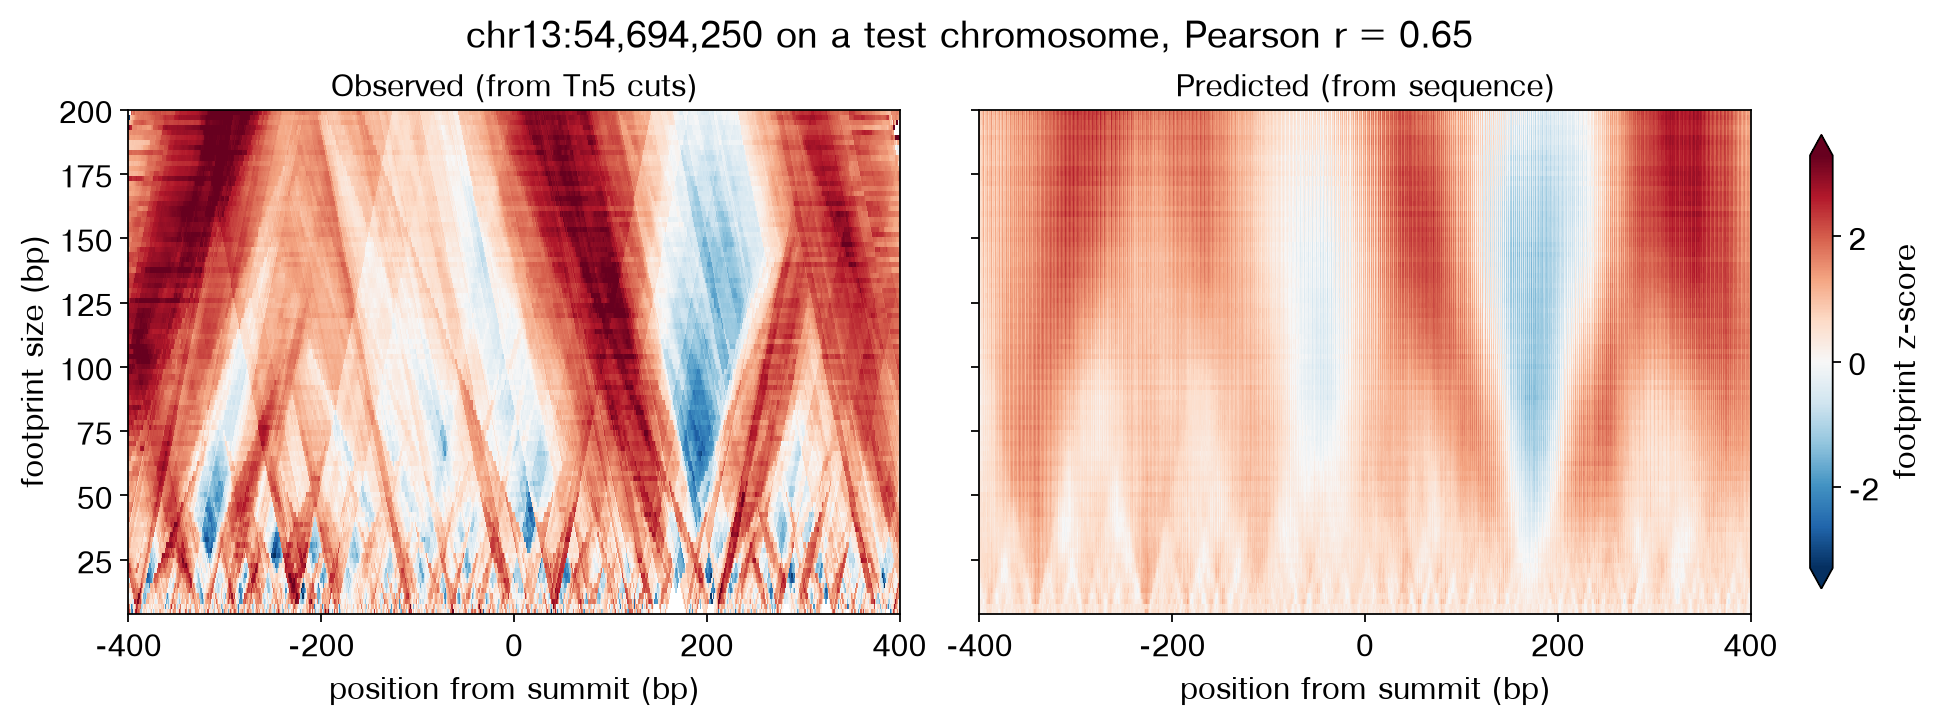

In [7]:
# One held-out window: observed footprint vs prediction.
i = int(np.argsort(test.coverage[:, 0])[-50])       # a well-covered test peak
X, y = test.centred()[i]
with torch.no_grad():
    pred, _ = model(X[None].to(DEVICE))
obs = s2p.multiscaleFoot(y[None, 0].to(DEVICE), y[None, 1].to(DEVICE),
                         np.arange(2, 101), target_model.to(DEVICE))[0]
pred = pred[0].float().cpu().numpy(); obs = obs.cpu().numpy()
r = np.corrcoef(np.nan_to_num(obs).ravel(), pred.ravel())[0, 1]
chrom, summit = test.peaks.chrom[i], int(test.peaks.summit[i])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True, layout='constrained')
ext = [-400, 400, 4, 200]                            # 800 bp around the summit; scales 2-100 = 4-200 bp
vm = np.nanpercentile(np.abs(obs), 99)               # one colour scale for both panels
for ax, M, t in ((axes[0], obs, 'Observed (from Tn5 cuts)'), (axes[1], pred, 'Predicted (from sequence)')):
    im = ax.imshow(M, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-vm, vmax=vm,
                   extent=ext, interpolation='nearest')
    ax.set_title(t); ax.set_xlabel('position from summit (bp)')
    ax.set_xticks(np.arange(-400, 401, 200))
axes[0].set_ylabel('footprint size (bp)')
cb = fig.colorbar(im, ax=axes, shrink=0.9, pad=0.02, extend='both')
cb.set_label('footprint z-score')
fig.suptitle(f'{chrom}:{summit:,} on a test chromosome, Pearson r = {r:.2f}')
plt.show()

## Part 5 · One LoRA state per domain

LoRA freezes the trained backbone and adds a low-rank update to every
convolution, generated from a cell state's embedding by a small network, so
one backbone serves every state. Each domain's state is its mean
iterative-LSI embedding; its coverage covariate is its log cuts in peaks
(z-scored), which a coverage-adjustment head absorbs first
(`coverage_warming`, scPrinter's schedule), because a footprint z-score grows
with depth and every domain has far fewer cuts than the pooled section.

This uses a light LoRA (rank 8, hidden width 64, learning rate 10⁻⁴: about
30 minutes on an H100 for six domains). scPrinter's defaults (rank 32, width
256, 3×10⁻⁵ with 8-step accumulation) are `add_lora(emb, coverages=cov)` and
`fit(..., lr=3e-5, accumulate=8, coverage_warming=5)`. The trained model is
cached in `WORK`.

In [8]:
%%time
groups = [np.flatnonzero(spot_domain == d) for d in DOMAINS]
per_domain = windows(peaks, groups)              # every (peak, domain) pair; item = peak * 6 + domain
tr6, va6, te6 = (per_domain.split(folds[s]) for s in ('train', 'valid', 'test'))
lsi = tiles.obsm['X_iterative_lsi']
emb = np.stack([lsi[g].mean(0) for g in groups])
emb = ((emb - emb.mean(0)) / emb.std(0)).astype(np.float32)
cov = np.log10(per_domain.coverage.sum(0))[:, None]
cov = ((cov - cov.mean()) / cov.std()).astype(np.float32)

lora = copy.deepcopy(model).cpu().add_lora(emb, coverages=cov, rank=8, hidden_dim=64)
import hashlib                                     # cache key: the domains and peaks it was trained on
key = hashlib.md5(spot_domain.astype(str).tobytes()
                  + peaks[['chrom', 'summit']].to_csv(index=False).encode()).hexdigest()[:10]
lora_ckpt, lora_hist_file = WORK / f'lora_domains_{key}.pt', WORK / f'lora_domains_{key}_history.tsv'
if lora_ckpt.exists() and lora_hist_file.exists():
    lora.load_state_dict(torch.load(lora_ckpt, map_location='cpu'))
    lora_hist = pd.read_csv(lora_hist_file, sep='\t')
    print('loaded cached domain LoRA')
else:
    res_lora = s2p.fit(lora, tr6, va6, epochs=8, patience=3, lr=1e-4, coverage_warming=2,
                       num_workers=6, device=DEVICE, target_model=target_model)
    lora, lora_hist = res_lora.model, res_lora.to_frame()
    torch.save(lora.state_dict(), lora_ckpt)
    lora_hist.to_csv(lora_hist_file, sep='\t', index=False)
lora = lora.to(DEVICE).eval()
n_lora = sum(p.numel() for n, p in lora.named_parameters() if 'A_embedding' in n or 'B_embedding' in n)
print(f'{len(per_domain):,} (peak, domain) windows; LoRA networks: {n_lora:,} parameters '
      f'(backbone: {sum(p.numel() for p in model.parameters()):,}, frozen)')

└─ Seq2PRINTDataset: 12,722 peaks x 6 group(s) (0 at contig edges, 4 outside coverage bounds dropped)


loaded cached domain LoRA
76,332 (peak, domain) windows; LoRA networks: 26,289,529 parameters (backbone: 11,756,644, frozen)
CPU times: user 29.5 s, sys: 963 ms, total: 30.5 s
Wall time: 25.7 s


**Every domain under every state.** On held-out chromosomes, each domain's
windows are predicted with each of the six LoRA states and with the bulk
model. If the state carries domain identity, a domain is predicted best by its
own state (the diagonal); if fine-tuning only adapted the model to thinner
data, every state would do equally well. Footprint profiles are scored with
scPrinter's metric (`evaluate`), coverage as the correlation of predicted and
observed log coverage across the domain's test peaks.

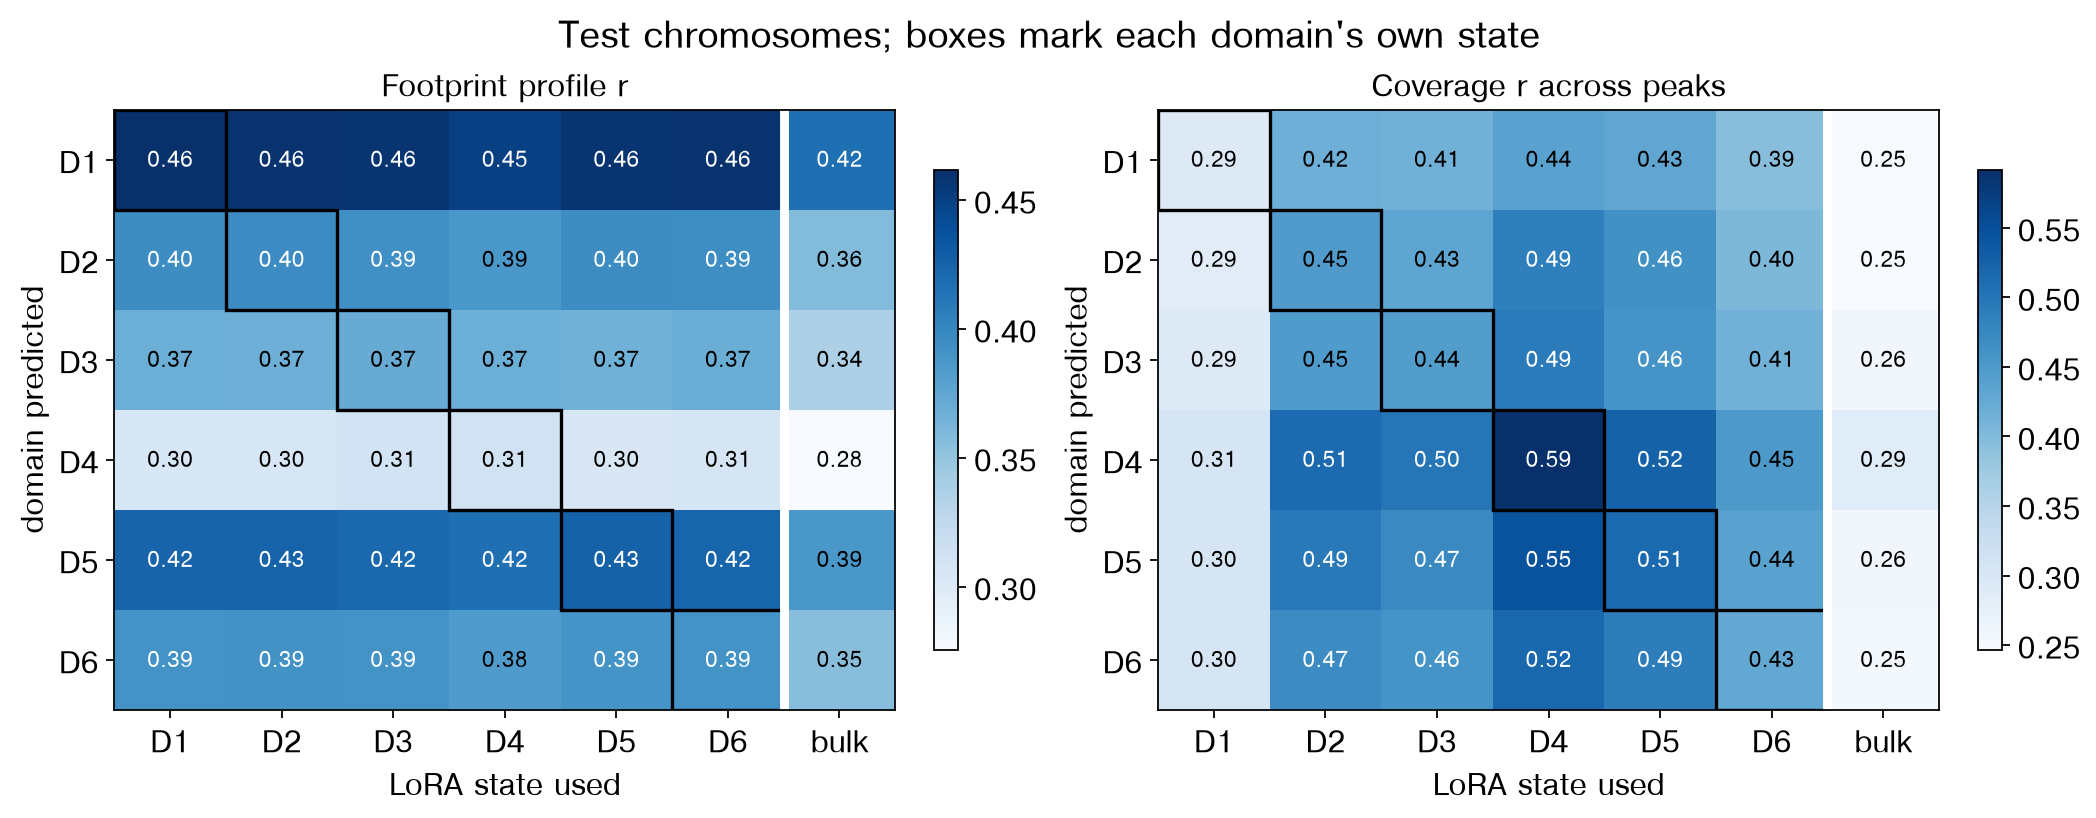

CPU times: user 7min 48s, sys: 1min 13s, total: 9min 2s
Wall time: 8min


In [9]:
%%time
class AsState(torch.utils.data.Dataset):
    # the same windows, conditioned on a chosen state
    def __init__(self, base, idx, state):
        self.base, self.idx, self.state = base, idx, state
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        X, y, _ = self.base[self.idx[i]]
        return X, y, torch.tensor(self.state)


ND, centred = len(DOMAINS), te6.centred()
nP = len(te6) // ND                                 # test peaks; item = peak * ND + domain
prof = pd.DataFrame(index=DOMAINS, columns=DOMAINS + ['bulk'], dtype=float)
obs_cov, pred_cov, bulk_cov = np.zeros((nP, ND)), np.zeros((nP, ND, ND)), np.zeros(nP)
with torch.no_grad():
    for g, d in enumerate(DOMAINS):
        idx = np.arange(g, len(te6), ND)
        for s in range(ND):
            prof.loc[d, DOMAINS[s]] = s2p.evaluate(lora, AsState(centred, idx, s),
                                                   target_model=target_model,
                                                   device=DEVICE)['profile_pearson']
        prof.loc[d, 'bulk'] = s2p.evaluate(model, AsState(centred, idx, g), target_model=target_model,
                                           device=DEVICE)['profile_pearson']
        for k in range(0, nP, 64):
            items = [centred[i] for i in idx[k:k + 64]]
            X = torch.stack([it[0] for it in items]).to(DEVICE)
            obs_cov[k:k + 64, g] = torch.log1p(torch.stack([it[1][0] for it in items]).sum(-1))
            for s in range(ND):
                pred_cov[k:k + 64, g, s] = lora(X, cells=torch.full((len(X),), s, device=DEVICE))[1].float().cpu()
            if g == 0:
                bulk_cov[k:k + 64] = model(X)[1].float().cpu()
covr = pd.DataFrame([[np.corrcoef(pred_cov[:, g, s], obs_cov[:, g])[0, 1] for s in range(ND)]
                     + [np.corrcoef(bulk_cov, obs_cov[:, g])[0, 1]] for g in range(ND)],
                    index=DOMAINS, columns=DOMAINS + ['bulk'])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, M, t in ((axes[0], prof, 'Footprint profile r'), (axes[1], covr, 'Coverage r across peaks')):
    v = M.to_numpy(float)
    im = ax.imshow(v, cmap='Blues', aspect='auto')
    for i in range(ND):
        for j in range(ND + 1):
            ax.text(j, i, f'{v[i, j]:.2f}', ha='center', va='center', fontsize=10,
                    color='w' if v[i, j] > v.min() + 0.6 * (v.max() - v.min()) else 'k')
        ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, ec='k', lw=1.5))
    ax.axvline(ND - 0.5, color='w', lw=4)
    ax.set_xticks(range(ND + 1), DOMAINS + ['bulk']); ax.set_yticks(range(ND), DOMAINS)
    ax.set_xlabel('LoRA state used'); ax.set_ylabel('domain predicted'); ax.set_title(t)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle('Test chromosomes; boxes mark each domain\'s own state')
plt.show()

Neither score shows domain identity. Footprint profile r barely depends on the
state (each row varies by 0.01 or less), but every LoRA state beats the bulk
model by 0.03-0.04: fine-tuning on per-domain data improves the predicted
footprint shapes, and the improvement is not domain-specific. For coverage the
columns dominate: the D4 state ranks peaks best in every domain and the D1
state worst. That is a property of how each state reweights the coverage head,
not of matching the domain.

**Between-domain differences.** The scores above mostly measure how well a
window's shape and level are predicted, which the bulk model already does.
The sharper test is whether the model predicts how the *same* peak differs
between domains. Two things are removed first: each peak's overall level
(what the bulk model predicts) and each domain's overall depth (domains range
from 5 to 38 million fragments, and the coverage covariate tells the model
that). What is left, the peak-by-domain interaction, is what only a domain
model can predict; the bulk model scores zero on it by construction.

Observed interactions are noisy at these depths, so the measure has a
ceiling: two independent Poisson draws of the same expected counts agree only
so well. The null is the same LoRA with the states shifted (each domain's
peaks predicted with another domain's state, for each of the five shifts).

In [10]:
kind = te6.peaks.merge(peaks[['chrom', 'summit', 'kind']], on=['chrom', 'summit'],
                       how='left')['kind'].to_numpy()


def interaction(a):
    # remove peak means and domain means: the peak-by-domain part
    return a - a.mean(1, keepdims=True) - a.mean(0, keepdims=True) + a.mean()


rng = np.random.default_rng(0)
ceiling_a, ceiling_b = (np.log1p(rng.poisson(np.expm1(obs_cov))) for _ in range(2))
own = pred_cov[:, np.arange(ND), np.arange(ND)]
shifted = [pred_cov[:, np.arange(ND), (np.arange(ND) + k) % ND] for k in range(1, ND)]
oi = interaction(obs_cov)
r = lambda u, v, m: np.corrcoef(u[m].ravel(), v[m].ravel())[0, 1]
rows = {}
for name, m in (('all test peaks', np.ones(nP, bool)), ('bulk peaks', kind == 'bulk'),
                ('domain peaks', kind == 'domain')):
    null = [r(oi, interaction(p), m) for p in shifted]
    rows[name] = {'LoRA, own state': r(oi, interaction(own), m),
                  'states shifted (mean of 5)': np.mean(null),
                  'states shifted (max of 5)': np.max(null),
                  'ceiling (two Poisson draws)': r(interaction(ceiling_a), interaction(ceiling_b), m)}
between = pd.DataFrame(rows).round(3)
between

,all test peaks,bulk peaks,domain peaks
"LoRA, own state",0.233,0.253,0.244
states shifted (mean of 5),-0.047,-0.051,-0.049
states shifted (max of 5),0.059,0.052,0.080
ceiling (two Poisson draws),0.831,0.800,0.854


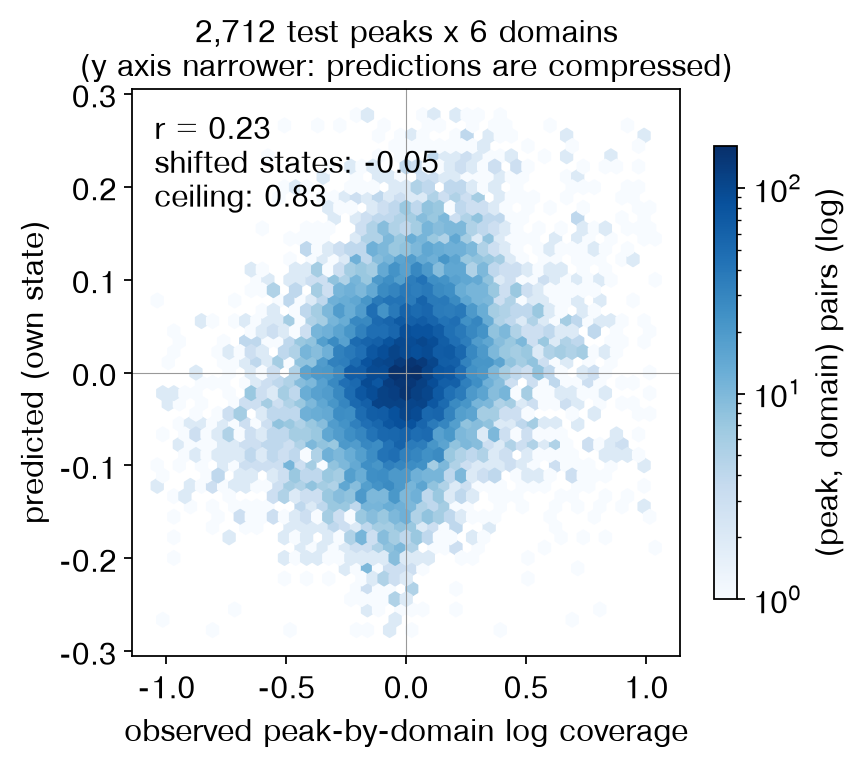

In [11]:
fig, ax = plt.subplots(figsize=(5.6, 5))
x, y = oi.ravel(), interaction(own).ravel()
lx, ly = np.percentile(np.abs(x), 99.5), np.percentile(np.abs(y), 99.5)
hb = ax.hexbin(x, y, gridsize=45, extent=(-lx, lx, -ly, ly), cmap='Blues', mincnt=1, bins='log')
ax.axhline(0, color='0.6', lw=0.5); ax.axvline(0, color='0.6', lw=0.5)
ax.set_xlabel('observed peak-by-domain log coverage')
ax.set_ylabel('predicted (own state)')
ax.text(0.04, 0.96, f"r = {between.loc['LoRA, own state', 'all test peaks']:.2f}\n"
        f"shifted states: {between.loc['states shifted (mean of 5)', 'all test peaks']:.2f}\n"
        f"ceiling: {between.loc['ceiling (two Poisson draws)', 'all test peaks']:.2f}",
        transform=ax.transAxes, va='top')
fig.colorbar(hb, ax=ax, shrink=0.8, label='(peak, domain) pairs (log)')
ax.set_title(f'{nP:,} test peaks x {ND} domains\n(y axis narrower: predictions are compressed)')
plt.tight_layout(); plt.show()

Here the state matters. With each domain's own state, LoRA predicts the
peak-by-domain interaction at r = 0.23 (0.25 on bulk peaks, 0.24 on domain
peaks); with the states shifted, r is -0.05 on average and at most 0.06. The
ceiling is 0.83, so this light LoRA recovers about a quarter of the
reproducible between-domain signal, and its predicted differences are
compressed (the y axis spans about a third of the x axis). scPrinter's
full-size LoRA, longer training and finer states are the obvious next steps.

## Part 6 · Motif effects across footprint sizes

`delta_effects` plants a motif's consensus at the centre of background
sequences (here 1,000 test-chromosome peaks) and averages how the predicted
footprints change, at every size and position, in -log10 p (scPrinter's
`seq2print_delta`). A TF leaves a narrow, small-radius footprint over its
site; nucleosome-scale changes show at large radii. Motifs are from JASPAR
2024 (vertebrates, non-redundant), downloaded once.

In [12]:
%%time
MEME = WORK / 'JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt'
if not MEME.exists():
    import urllib.request
    urllib.request.urlretrieve('https://jaspar.elixir.no/download/data/2024/CORE/' + MEME.name, MEME)
jaspar = {}
for block in MEME.read_text().split('MOTIF ')[1:]:
    head, *lines = block.strip().splitlines()
    mid, name = head.split()[:2]
    rows_ = [l.split() for l in lines if re.fullmatch(r'\s*([0-9.]+\s+){3}[0-9.]+\s*', l)]
    jaspar.setdefault(name.upper(), np.array(rows_, float).T)          # [4, width]

TF = slice(0, 30)                                     # footprint radius 2-31 bp: TF-sized
MOTIFS = ['CTCF', 'RFX3', 'NFIA', 'SOX9', 'NEUROD2', 'TBR1', 'DLX2', 'LHX2', 'MEF2C', 'POU3F2',
          'FOXC1', 'NRF1', 'YY1', 'FOS::JUN', 'EGR1', 'KLF4']
motifs = {m: jaspar[m] for m in MOTIFS}
test_X = np.stack([test.centred()[i][0].numpy() for i in range(len(test))])
backgrounds = test_X[np.random.default_rng(0).choice(len(test_X), 1000, replace=False)]
delta_foot, delta_cov = s2p.delta_effects(model, motifs, backgrounds)
summary = pd.DataFrame({
    'TF-size footprint at the site': {m: f[TF, 390:410].mean() for m, f in delta_foot.items()},
    'nucleosome-size change (±100 bp)': {m: f[60:, 300:500].mean() for m, f in delta_foot.items()},
    'coverage (log)': delta_cov}).sort_values('TF-size footprint at the site', ascending=False)
summary.round(3)

CPU times: user 1min 4s, sys: 796 ms, total: 1min 4s
Wall time: 6.83 s


,TF-size footprint at the site,nucleosome-size change (±100 bp),coverage (log)
RFX3,0.073,-0.018,0.010
POU3F2,0.053,0.039,-0.011
MEF2C,0.051,0.043,-0.014
YY1,0.046,0.022,-0.008
LHX2,0.036,0.015,-0.003
DLX2,0.034,0.010,-0.003
CTCF,0.025,-0.023,0.012
NFIA,0.017,0.003,-0.001
NEUROD2,0.013,0.005,-0.003
NRF1,0.013,-0.043,0.029


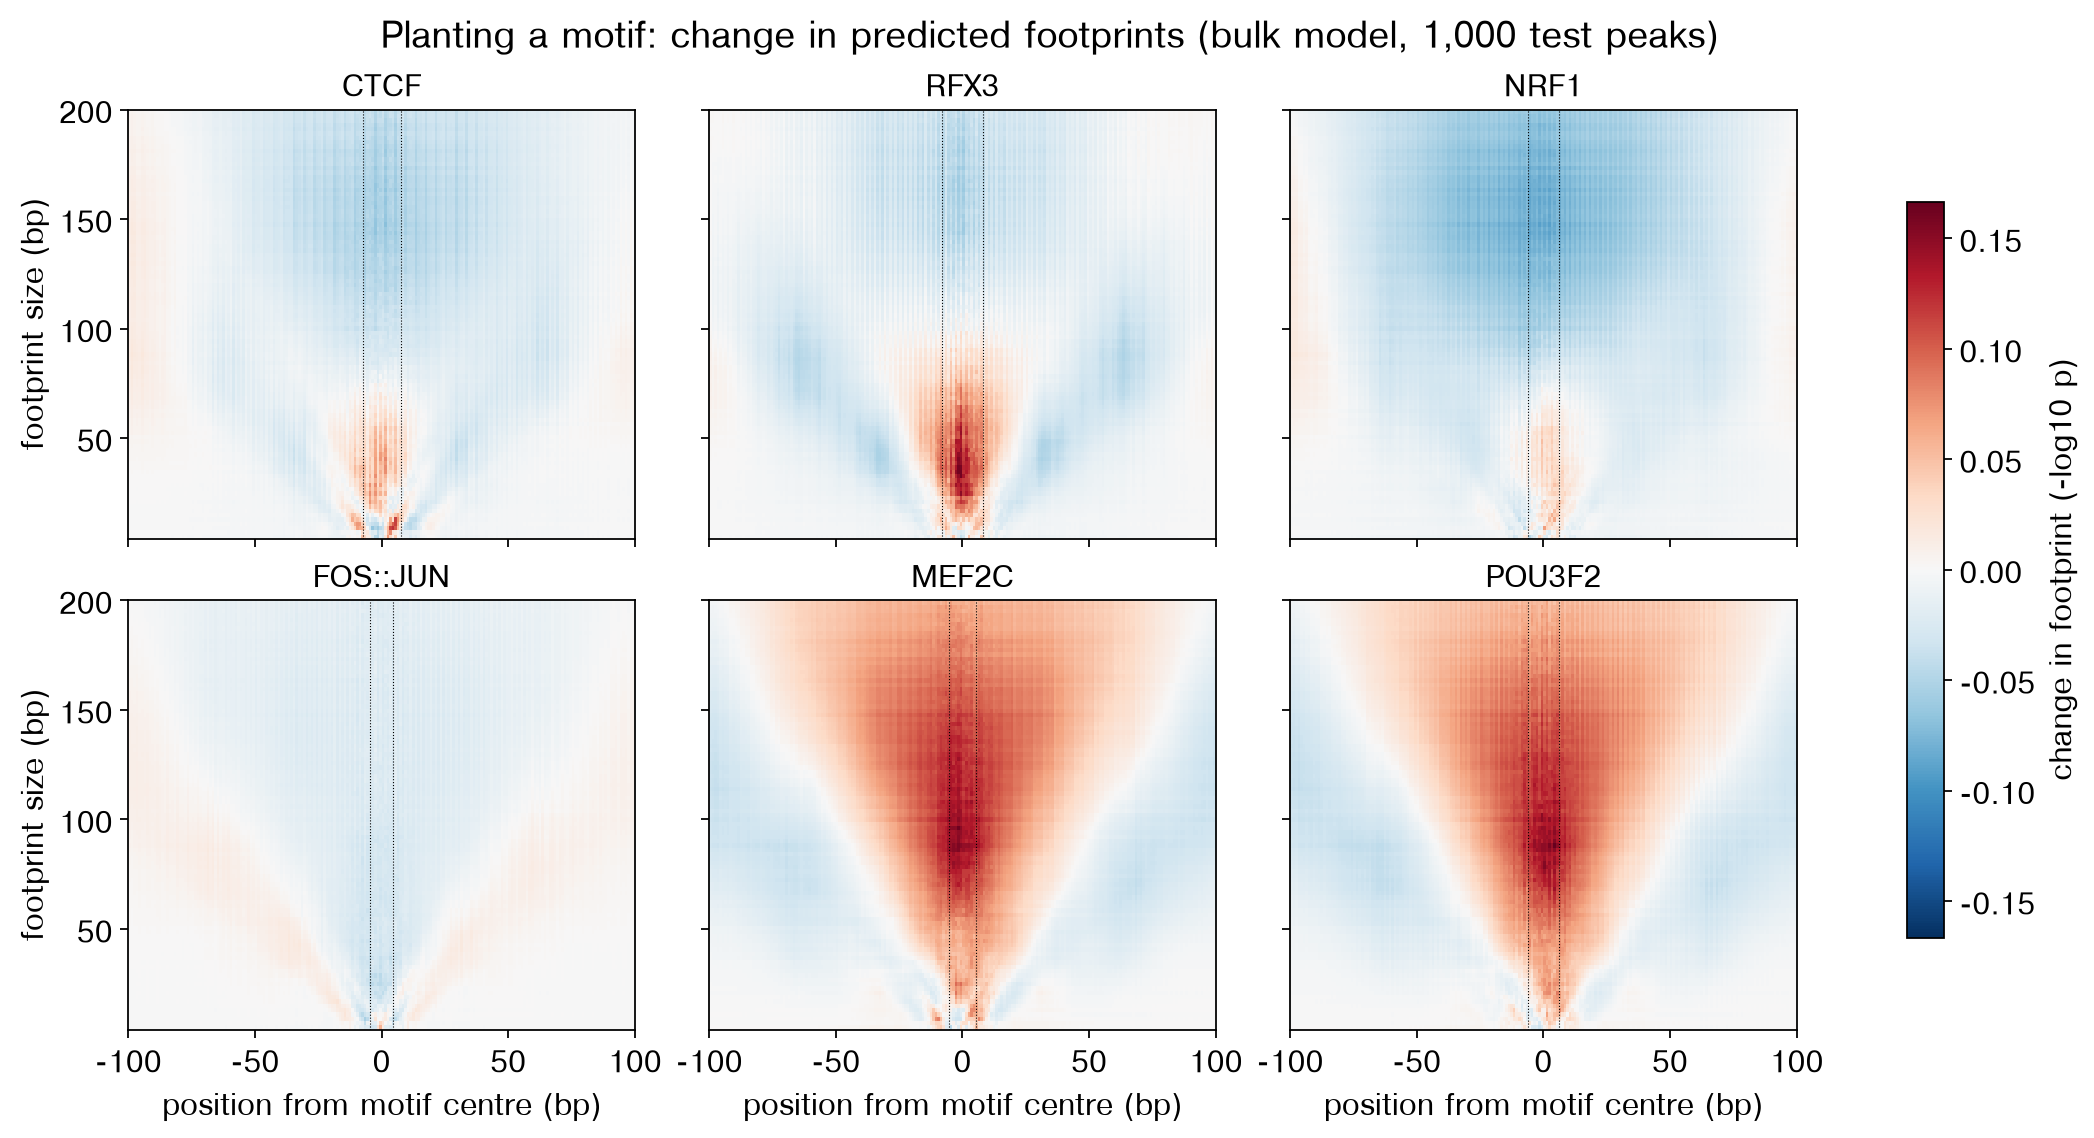

In [13]:
show = ['CTCF', 'RFX3', 'NRF1', 'FOS::JUN', 'MEF2C', 'POU3F2']
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True, layout='constrained')
vm = max(np.abs(delta_foot[m][:, 300:500]).max() for m in show)
for ax, m in zip(axes.ravel(), show):
    im = ax.imshow(delta_foot[m][:, 300:500], origin='lower', aspect='auto', cmap='RdBu_r',
                   vmin=-vm, vmax=vm, extent=[-100, 100, 4, 200], interpolation='nearest')
    w = motifs[m].shape[1]
    ax.axvline(-w / 2, color='k', lw=0.5, ls=':'); ax.axvline(w / 2, color='k', lw=0.5, ls=':')
    ax.set_title(m)
for ax in axes[1]:
    ax.set_xlabel('position from motif centre (bp)')
for ax in axes[:, 0]:
    ax.set_ylabel('footprint size (bp)')
fig.colorbar(im, ax=axes, shrink=0.8, label='change in footprint (-log10 p)')
fig.suptitle('Planting a motif: change in predicted footprints (bulk model, 1,000 test peaks)')
plt.show()

RFX3 and CTCF leave a TF-sized footprint over the site and lower the
nucleosome-scale signal around it: a factor that binds and keeps the site
open. NRF1 mostly clears nucleosome-scale signal. MEF2C and POU3F2, both
AT-rich motifs, raise predicted footprints at every size; FOS::JUN changes
little in this tissue. The effects are small (at most about 0.15 in -log10 p)
because the model is trained on 10,000 peaks of one section; scPrinter trains
on genome-wide peak sets.

## Part 7 · Exactness and checkpoint compatibility

The network blocks are scPrinter's own, vendored unchanged, and the
assembled model has scPrinter's layout. So the bulk model trained above
loads into **scPrinter's** `seq2PRINT` class with `strict=True`, and the
two must predict identically — checked here on real held-out windows.
The training targets get the same check. `tests/test_seq2print.py` covers
the LoRA model, the EMA (against `ema_pytorch`) and the loss as well.

Set `SCPRINTER_SRC` to the `scprinter/` directory of a scPrinter clone to
run it.

In [14]:
SRC = os.environ.get('SCPRINTER_SRC')
if not SRC:
    print('SCPRINTER_SRC not set — skipping.')
else:
    import ast, importlib, shutil, types, tempfile
    root = pathlib.Path(tempfile.mkdtemp()); pkg = root / 'scp_up'
    (pkg / 'seq').mkdir(parents=True)
    (pkg / '__init__.py').write_text(''); (pkg / 'seq' / '__init__.py').write_text('')
    for f in ('Models.py', 'Modules.py', 'Functions.py', 'minimum_footprint.py'):
        shutil.copy(pathlib.Path(SRC) / 'seq' / f, pkg / 'seq' / f)
    text = (pathlib.Path(SRC) / 'utils.py').read_text(); lines = text.splitlines(keepends=True)
    fn = next(n for n in ast.parse(text).body if isinstance(n, ast.FunctionDef) and n.name == 'rz_conv_torch')
    (pkg / 'utils.py').write_text('import torch\n\n' + ''.join(lines[fn.lineno - 1:fn.end_lineno]))
    sys.modules.setdefault('wandb', types.ModuleType('wandb')); sys.path.insert(0, str(root))
    UM = importlib.import_module('scp_up.seq.Modules')
    UModels = importlib.import_module('scp_up.seq.Models')
    Umf = importlib.import_module('scp_up.seq.minimum_footprint')

    # scPrinter's construct_model_from_config, with its published defaults
    dil = lambda x: 2 ** (x + 1)
    theirs = UModels.seq2PRINT(
        dna_cnn_model=UM.DNA_CNN(n_filters=1024),
        hidden_layer_model=UM.DilatedCNN(n_filters=1024, bottleneck=1024, n_layers=8, kernel_size=3,
                                         groups=8, activation=torch.nn.GELU(), batch_norm=True,
                                         residual=True, rezero=False, dilation_func=dil,
                                         batch_norm_momentum=0.1, inception=[True] * 8,
                                         inception_version=2),
        profile_cnn_model=UM.Footprints_head(1024, kernel_size=1, n_scales=99),
        dna_len=model.dna_len, output_len=800)
    theirs.load_state_dict(model.state_dict(), strict=True)
    theirs = theirs.to(DEVICE).eval(); model.eval()

    same_pred = same_tgt = True
    tm_up = Umf.dispModel({str(r): {**{k: p[k] for k in ('featureMean', 'featureSD', 'targetMean', 'targetSD')},
                                    'modelWeights': [torch.from_numpy(w).float() for w in p['weights']]}
                           for r, p in dispersion.params.items()}).to(DEVICE)
    tm = target_model.to(DEVICE)
    loader = torch.utils.data.DataLoader(test.centred(), batch_size=64)
    n = 0
    with torch.no_grad():
        for b, (Xb, yb) in enumerate(loader):
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            a, c = model(Xb), theirs(Xb)
            same_pred &= torch.equal(a[0], c[0]) and torch.equal(a[1], c[1])
            ta = s2p.multiscaleFoot(yb[:, 0], yb[:, 1], np.arange(2, 101), tm)
            tb = Umf.multiscaleFoot(yb[:, 0], yb[:, 1], np.arange(2, 101), tm_up)
            same_tgt &= torch.equal(torch.nan_to_num(ta, 123.), torch.nan_to_num(tb, 123.))
            n += len(Xb)
            if b == 9:
                break
    print(f'{n} held-out windows: predictions identical to scPrinter: {same_pred}; '
          f'targets identical: {same_tgt}')

640 held-out windows: predictions identical to scPrinter: True; targets identical: True


## Summary

| | |
|---|---|
| Data | GSE308623 `P2S1`, mouse brain P2 spatial ATAC, 7,131 spots |
| Domains | 6, from smoothed BiRMT-2 + k-means; named by marker promoters |
| Peaks | 10,000 bulk peaks + 600 domain-enriched peaks per domain |
| Split | scPrinter's mm10 fold 0, whole chromosomes |
| Bulk model | scPrinter's architecture; trained weights from Hugging Face |
| LoRA per domain | peak-by-domain coverage r = 0.23 (states shifted -0.05, ceiling 0.83); footprint shapes +0.03-0.04 over bulk, not domain-specific |
| Delta effects | motif planted into 1,000 test peaks (bulk model); footprint change at every size |
| Exactness | predictions and targets equal to scPrinter's on held-out windows |